# PyTorch 综合作业一

已完成全部 7 题的代码、断言自检、图表和分析。请从头顺序运行；Notebook 可从 homework1 目录或仓库根目录启动。

默认自动选择 CUDA（可用时）或 CPU；第 5、6 题的小型温度实验固定在 CPU 上。可用环境变量 HOMEWORK_DEVICE=cpu 强制 CPU，或 HOMEWORK_DEVICE=cuda 要求 CUDA。CPU 环境会明确跳过第 4 题的显存测量，不伪造 GPU 数据。

本机执行结果保存在代码单元输出中。第 3 题 CUDA 性能比较和第 4 题 CUDA 显存测量的代码已经准备好，但须在 GPU 服务器上实际验证；n=5000 是可选的高耗时扩展实验，不是必跑任务。


In [1]:
import copy
import csv
import os
import re
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from IPython.display import Markdown, display

torch.manual_seed(42)
np.random.seed(42)
torch.set_num_threads(1)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

required_files = ("Pride and Prejudice.txt", "python_chess_init.py", "winequality-white.csv")
data_candidates = (Path.cwd(), Path.cwd() / "homework1")
DATA_DIR = next(
    (path for path in data_candidates if all((path / name).is_file() for name in required_files)),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError("请从 homework1 或仓库根目录启动，并保留作业附带的数据文件。")

requested_device = os.environ.get("HOMEWORK_DEVICE", "auto")
if requested_device not in {"auto", "cpu", "cuda"}:
    raise ValueError("HOMEWORK_DEVICE 只能是 auto、cpu 或 cuda。")
if requested_device == "cuda" and not torch.cuda.is_available():
    raise RuntimeError("请求了 CUDA，但当前 PyTorch 环境无法使用 CUDA。")
device = torch.device(
    "cuda" if requested_device == "cuda" or
    (requested_device == "auto" and torch.cuda.is_available()) else "cpu"
)
if device.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = False

def synchronize_device():
    if device.type == "cuda":
        torch.cuda.synchronize(device)

print(f"Python: {sys.version.split()[0]}, PyTorch: {torch.__version__}")
print(f"device: {device}, CPU threads: {torch.get_num_threads()}, DATA_DIR: {DATA_DIR}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(device)}")
else:
    print("CPU 模式：第 3 题的 CUDA 计时、第 4 题的显存测量留待 GPU 服务器验证。")


Python: 3.10.0, PyTorch: 2.8.0+cu128
device: cuda, CPU threads: 1, DATA_DIR: /home/renxuanyu/deeplearning/homework1
GPU: NVIDIA RTX A6000


## 1. 张量基础与视图操作

完成下面的代码，并在结果下方回答问题：

1. 使用 `list(range(9))` 创建一维张量 `a`，预测并验证它的 `size`、`storage_offset` 和 `stride`。
2. 创建 `b = a.view(3, 3)`，写出 `b[1, 1]` 的值。
3. 创建 `c = b[1:, 1:]`，预测并验证它的 `size`、`storage_offset` 和 `stride`。

请说明 `view` 和切片是否复制了数据，以及 `a`、`b`、`c` 之间的存储关系。

In [2]:
a = torch.tensor(list(range(9)))
b = a.view(3, 3)
c = b[1:, 1:]

predicted_layouts = {
    "a": ((9,), 0, (1,)),
    "b": ((3, 3), 0, (3, 1)),
    "c": ((2, 2), 4, (3, 1)),
}
for name, tensor in (("a", a), ("b", b), ("c", c)):
    observed = (tuple(tensor.size()), tensor.storage_offset(), tensor.stride())
    assert observed == predicted_layouts[name]
    print(f"{name}: predicted = {predicted_layouts[name]}, observed = {observed}")
print("b[1, 1] =", b[1, 1].item())
print("c =", c)
assert b[1, 1].item() == 4
assert a.untyped_storage().data_ptr() == b.untyped_storage().data_ptr()
assert a.untyped_storage().data_ptr() == c.untyped_storage().data_ptr()
assert not c.is_contiguous()

original_value = a[4].item()
c[0, 0] = -99
assert a[4].item() == b[1, 1].item() == -99
c[0, 0] = original_value
torch.testing.assert_close(a, torch.arange(9))
print("第 1 题自检通过：形状、偏移、步长和共享存储均符合预测。")


a: predicted = ((9,), 0, (1,)), observed = ((9,), 0, (1,))
b: predicted = ((3, 3), 0, (3, 1)), observed = ((3, 3), 0, (3, 1))
c: predicted = ((2, 2), 4, (3, 1)), observed = ((2, 2), 4, (3, 1))
b[1, 1] = 4
c = tensor([[4, 5],
        [7, 8]])
第 1 题自检通过：形状、偏移、步长和共享存储均符合预测。


### 第 1 题分析

a 的 size=(9,)、storage_offset=0、stride=(1,)；b 的 size=(3,3)、offset=0、stride=(3,1)，所以 b[1,1]=4。c 的 size=(2,2)、offset=4、stride=(3,1)，内容为 [[4,5],[7,8]]。

view 只改变形状/步长元数据，本例的基本切片也不复制数据；a、b、c 共享同一底层存储。c 的元素地址按 4+行号×3+列号×1 计算，行之间有间隔，因此 c 不是连续张量。改变 c[0,0] 会同时改变 a[4] 和 b[1,1]，代码验证后已恢复原值。这里结论针对 view 和基本切片；高级索引、clone 等操作不应一概视为共享存储。


## 2. 文本索引与独热编码

使用 `Pride and Prejudice.txt` 和 `python_chess_init.py` 完成任务。该 Python 源代码文件位于当前 Notebook 同一目录：

1. 用正则表达式提取两个文件中的单词并建立词汇表索引。
2. 比较两个词汇表的大小，并解释可能的原因。
3. 为 Python 源代码创建独热编码。
4. 分析独热编码丢失了哪些信息，并比较源代码与自然语言文本中的信息损失。

请读取 `DATA_DIR / "python_chess_init.py"`，并根据实际文件内容建立词汇表和独热编码。可以适当限制独热编码的 token 数量，避免生成过大的稠密矩阵。

In [3]:
token_pattern = re.compile(r"[A-Za-z_][A-Za-z_0-9]*")
novel_text = (DATA_DIR / "Pride and Prejudice.txt").read_text(encoding="utf-8-sig")
python_text = (DATA_DIR / "python_chess_init.py").read_text(encoding="utf-8-sig")
novel_tokens = token_pattern.findall(novel_text)
python_tokens = token_pattern.findall(python_text)
novel_vocab = sorted(set(novel_tokens))
python_vocab = sorted(set(python_tokens))
novel_word_to_index = {word: index for index, word in enumerate(novel_vocab)}
python_word_to_index = {word: index for index, word in enumerate(python_vocab)}
novel_token_ids = torch.tensor([novel_word_to_index[word] for word in novel_tokens])
python_token_ids = torch.tensor([python_word_to_index[word] for word in python_tokens])

max_one_hot_tokens = 1024
encoded_ids = python_token_ids[:max_one_hot_tokens]
python_one_hot = torch.zeros((encoded_ids.numel(), len(python_vocab)), dtype=torch.uint8)
python_one_hot.scatter_(1, encoded_ids.unsqueeze(1), 1)

assert novel_token_ids.dtype == python_token_ids.dtype == torch.int64
assert python_one_hot.shape == (min(max_one_hot_tokens, len(python_tokens)), len(python_vocab))
assert torch.all(python_one_hot.sum(dim=1) == 1)
torch.testing.assert_close(python_one_hot.argmax(dim=1), encoded_ids)
decoded_tokens = [python_vocab[index] for index in python_one_hot.argmax(dim=1).tolist()]
assert decoded_tokens == python_tokens[:max_one_hot_tokens]

print(f"小说：{len(novel_tokens):,} tokens，{len(novel_vocab):,} 个不同单词")
print(f"Python：{len(python_tokens):,} tokens，{len(python_vocab):,} 个不同单词")
print("Python 前 12 个 tokens：", python_tokens[:12])
print("对应索引：", python_token_ids[:12].tolist())
print(f"独热编码形状：{tuple(python_one_hot.shape)}，dtype：{python_one_hot.dtype}")
print(f"独热矩阵大小：{python_one_hot.numel() * python_one_hot.element_size() / 2**20:.2f} MiB")
print(f"为控制内存，只编码前 {encoded_ids.numel()} 个 token；词汇表仍来自完整文件。")
print("第 2 题自检通过：独热编码逐行和为 1，并且可无损还原已编码 token。")


小说：125,988 tokens，7,191 个不同单词
Python：15,953 tokens，1,717 个不同单词
Python 前 12 个 tokens： ['A', 'chess', 'library', 'with', 'move', 'generation', 'and', 'validation', 'Polyglot', 'opening', 'book', 'probing']
对应索引： [0, 767, 1148, 1672, 1194, 994, 629, 1641, 369, 1253, 705, 1343]
独热编码形状：(1024, 1717)，dtype：torch.uint8
独热矩阵大小：1.68 MiB
为控制内存，只编码前 1024 个 token；词汇表仍来自完整文件。
第 2 题自检通过：独热编码逐行和为 1，并且可无损还原已编码 token。


### 第 2 题分析

- 两份文件使用相同的正则表达式，保留大小写及标识符内部的下划线、数字；词汇表排序后编号，因此结果可复现。这里提取的是词形/标识符，不是 Python 语法分析器意义上的完整 token。
- 实际提取小说 125988 个 token、7191 个不同词，Python 文件 15953 个 token、1717 个不同词；独热矩阵为 1024×1717，约 1.68 MiB。小说文本更长，包含多样的叙述、人物及词形；Python 文件反复使用关键字、函数名与变量名，但也包含注释、文档字符串和特有标识符。因此差异受文件长度、主题、重复程度和分词规则共同影响，不能仅凭词汇表大小判断语言复杂度。
- **独热编码本身不丢失已编码 token 的身份**：保留词表和矩阵行顺序时，可以通过 argmax 完整还原这一段 token 序列；它不表达词义相近程度，也不主动建模上下文，不能把“没有语义表示”误说成“词序必然丢失”。
- 信息丢失主要发生在正则分词：空格、换行、标点、运算符、独立数字、字符串引号等被丢弃。自然语言损失句界、语气和排版；Python 则还会丢失缩进块、操作符、字面量和语法结构，通常无法据此还原可执行代码。
- 仅为前 1024 个 token 建立稠密独热矩阵，截断之外的代码没有被这个矩阵表示。使用 uint8 节省存储；如输入神经网络需按需转为浮点类型，实际大规模任务通常采用索引加 Embedding。


## 3. 矩阵乘法性能比较

比较以下三种计算两个矩阵乘积的方法：

- 完全向量化：使用 `A @ B`
- 部分向量化：外层循环遍历行，行内使用向量运算
- 标量化：双重循环逐元素计算

要求：

- 记录三种方法的运行时间并绘制柱状图。
- GPU 上使用 `torch.cuda.synchronize()` 保证计时准确。
- 验证三种方法结果一致。
- 分析向量化、Python 循环、底层并行库和设备同步对性能的影响。

默认规模应适合课堂环境快速运行；可将 `n` 调大到 `5000` 做额外实验。

Fully vectorized    : 0.034 ms, max error = 0.000e+00
Row vectorized      : 3.653 ms, max error = 7.629e-06
Elementwise loops   : 469.176 ms, max error = 7.629e-06


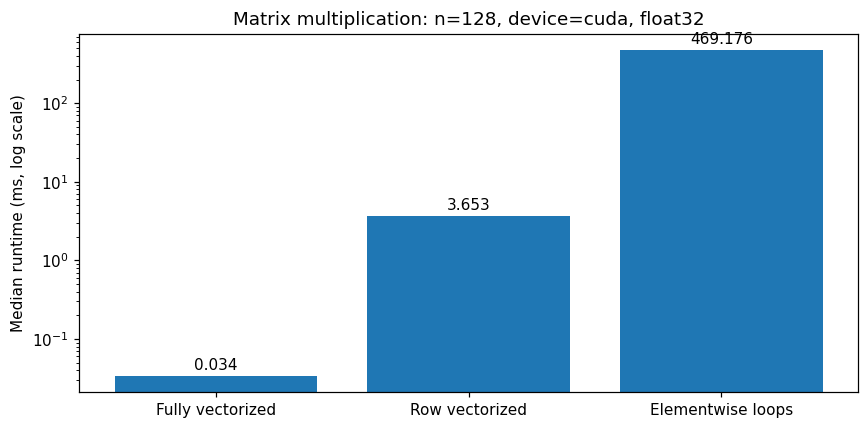

第 3 题自检通过：三种结果在浮点容差内一致。


In [4]:
torch.manual_seed(42)
n = 128
benchmark_repeats = 3
A = torch.randn(n, n, device=device)
B = torch.randn(n, n, device=device)

def fully_vectorized(left, right):
    return left @ right

def row_vectorized(left, right):
    result = torch.empty((left.shape[0], right.shape[1]), dtype=left.dtype, device=left.device)
    for row_index in range(left.shape[0]):
        result[row_index] = left[row_index] @ right
    return result

def elementwise_product(left, right):
    result = torch.empty((left.shape[0], right.shape[1]), dtype=left.dtype, device=left.device)
    for row_index in range(left.shape[0]):
        for column_index in range(right.shape[1]):
            result[row_index, column_index] = torch.dot(left[row_index], right[:, column_index])
    return result

matmul_methods = {
    "Fully vectorized": fully_vectorized,
    "Row vectorized": row_vectorized,
    "Elementwise loops": elementwise_product,
}
benchmark_outputs = {}
benchmark_times = {}
with torch.no_grad():
    for method_name, operation in matmul_methods.items():
        warmup_output = operation(A, B)
        synchronize_device()
        del warmup_output
        durations = []
        for repeat_index in range(benchmark_repeats):
            synchronize_device()
            started_at = time.perf_counter()
            result = operation(A, B)
            synchronize_device()
            durations.append(time.perf_counter() - started_at)
        benchmark_times[method_name] = float(np.median(durations))
        benchmark_outputs[method_name] = result.detach().cpu()

for method_name, result in benchmark_outputs.items():
    torch.testing.assert_close(result, benchmark_outputs["Fully vectorized"], rtol=1e-4, atol=1e-4)
    max_error = (result - benchmark_outputs["Fully vectorized"]).abs().max().item()
    print(f"{method_name:20s}: {benchmark_times[method_name] * 1000:.3f} ms, max error = {max_error:.3e}")

figure, axis = plt.subplots(figsize=(8, 4))
bars = axis.bar(list(benchmark_times), np.array(list(benchmark_times.values())) * 1000)
axis.set_yscale("log")
axis.set_ylabel("Median runtime (ms, log scale)")
axis.set_title(f"Matrix multiplication: n={n}, device={device}, float32")
for bar, elapsed in zip(bars, benchmark_times.values()):
    axis.annotate(f"{elapsed * 1000:.3f}", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                  xytext=(0, 4), textcoords="offset points", ha="center")
figure.tight_layout()
plt.show()
print("第 3 题自检通过：三种结果在浮点容差内一致。")


### 第 3 题分析

- 比较相同的 float32 输入，先预热，每种方法重复 3 次，报告中位数；输入生成、结果搬回 CPU 和画图均不计入计时。实际耗时见上方输出，不把本机 CPU 结果冒充 GPU 结果。
- 完全向量化把工作交给一次底层矩阵乘法；逐行方法调用 n 次向量—矩阵运算；双循环方法为每个输出元素调用一次点积，共 n² 次。这里的“标量化”指逐个生成输出元素，点积归约本身仍由 PyTorch 实现，不是额外增加第三层 Python 循环。
- Python 循环、索引及大量小算子调用产生调度开销。底层 BLAS/cuBLAS 可利用分块、缓存、SIMD 或 GPU 并行，通常使整矩阵计算最快。本 Notebook 对小规模 CPU 实验固定为单线程以减少线程调度开销，并非宣称底层只能单线程。
- CUDA 运算异步提交，因此在计时前后同步，避免只测到提交开销或把前一项工作算入本次。同步不放在每个内层点积后，以免人为增加额外开销；小矩阵的 GPU 运行也未必快于 CPU。
- 不同归约顺序会产生浮点误差，故检查容差内一致而非逐位相等。n=5000 只是可选额外实验：双循环含 2500 万次小算子调用，CPU/GPU 上都可能很慢，不作为默认运行要求。


## 4. 内存管理

对于矩阵 `A`、`B`、`C`，比较下面两种实现：

```python
C = A @ B + C
```

和原地更新实现：

```python
C.addmm_(A, B)
```

要求：

- 比较两种实现的结果是否一致。
- 在 CUDA 环境下比较峰值显存和当前显存。
- 解释原地操作的内存优势及其限制。
- 如果没有 GPU，完成 CPU 版本的结果验证，并说明无法直接读取 CUDA 显存。

In [5]:
torch.manual_seed(42)
memory_n = 1024
memory_A = torch.randn(memory_n, memory_n, device=device)
memory_B = torch.randn(memory_n, memory_n, device=device)
memory_C_initial = torch.randn(memory_n, memory_n, device=device)

def compare_memory_update(inplace):
    current_C = memory_C_initial.clone()
    initial_pointer = current_C.data_ptr()
    synchronize_device()
    if device.type == "cuda":
        baseline_allocated = torch.cuda.memory_allocated(device)
        torch.cuda.reset_peak_memory_stats(device)
    with torch.no_grad():
        if inplace:
            current_C.addmm_(memory_A, memory_B)
        else:
            current_C = memory_A @ memory_B + current_C
    synchronize_device()
    if inplace:
        assert current_C.data_ptr() == initial_pointer
    else:
        assert current_C.data_ptr() != initial_pointer
    stats = None
    if device.type == "cuda":
        stats = {
            "baseline_MiB": baseline_allocated / 2**20,
            "current_MiB": torch.cuda.memory_allocated(device) / 2**20,
            "peak_MiB": torch.cuda.max_memory_allocated(device) / 2**20,
            "extra_peak_MiB": (torch.cuda.max_memory_allocated(device) - baseline_allocated) / 2**20,
            "reserved_MiB": torch.cuda.memory_reserved(device) / 2**20,
        }
    return current_C.detach().cpu(), stats

if device.type == "cuda":
    for inplace_mode in (False, True):
        warmup_result, _ = compare_memory_update(inplace_mode)
        del warmup_result
    torch.cuda.empty_cache()

out_of_place_C, out_of_place_memory = compare_memory_update(False)
inplace_C, inplace_memory = compare_memory_update(True)
torch.testing.assert_close(out_of_place_C, inplace_C, rtol=1e-4, atol=1e-4)
print(f"最大绝对差：{(out_of_place_C - inplace_C).abs().max().item():.3e}")
if device.type == "cuda":
    for label, statistics in (("C = A @ B + C", out_of_place_memory), ("C.addmm_(A, B)", inplace_memory)):
        print(label, {key: round(value, 3) for key, value in statistics.items()})
else:
    print("当前为 CPU，只验证结果和数据指针；没有 CUDA 显存，不能读取或推断 CUDA 峰值。")
print("第 4 题自检通过：结果一致，addmm_ 保留 C 的存储地址。")
del memory_A, memory_B, memory_C_initial


最大绝对差：1.526e-05
C = A @ B + C {'baseline_MiB': 24.25, 'current_MiB': 24.25, 'peak_MiB': 32.25, 'extra_peak_MiB': 8.0, 'reserved_MiB': 42.0}
C.addmm_(A, B) {'baseline_MiB': 24.25, 'current_MiB': 24.25, 'peak_MiB': 24.25, 'extra_peak_MiB': 0.0, 'reserved_MiB': 42.0}
第 4 题自检通过：结果一致，addmm_ 保留 C 的存储地址。


### 第 4 题分析

- 两个分支分别从相同的初始 C 克隆开始，避免连续更新造成输入不同。CPU 自检验证数值一致，且 addmm_ 不改变 C 的数据地址；它并不等价于直接测得显存节省。
- 表达式 C = A @ B + C 通常需要矩阵乘法的中间结果及新的输出；addmm_ 把乘加融合并覆盖 C，避免另外保存这些完整输出矩阵。一次 1024×1024 的 float32 矩阵约占 4 MiB，但具体峰值还受后端工作区及分配器影响。
- CUDA 分支先预热、同步，并在每种方法创建好输入后分别记录 baseline、重置峰值。extra_peak 是峰值减去该次基线，更适合公平比较；current 为运算完成且结果仍存活时的已分配显存，两种写法的 current 可能相近。reserved 是缓存分配器保留量，不能直接当作活跃张量用量。
- 原地操作会影响共享存储的其他视图，要求形状、类型兼容，并可能覆盖自动求导保存的中间值。需要梯度的叶子张量通常不能这样原地更新；本实验明确在 no_grad 中进行，不能照搬到任意训练计算图。
- 本机没有 CUDA，因此没有填写虚构显存数值。服务器上选择 CUDA 后重新运行本节，才可观察实际 current/peak/extra_peak。


## 5. Chapter 4：温度数据上的二次模型

下面的代码来自课程示例，已经给出数据预处理、线性模型、损失函数和训练循环。请直接在此基础上完成题目：

1. 将模型改写为 `w2 * t_u ** 2 + w1 * t_u + b`。
2. 分别训练线性模型和二次模型，比较最终训练损失与验证损失。
3. 用 Matplotlib 在同一张图中绘制 epoch 与训练/验证损失的关系。
4. 分析二次模型的结果是更好还是更差，并说明过拟合风险。

代码中的数据划分、输入缩放、损失函数和训练循环请保留；只修改或补充必要部分。

Linear: params=[4.539682388305664, -11.823715209960938], train MSE=9.441027, val MSE=178.924667
Quadratic: params=[0.5234943628311157, -0.7034749388694763, -0.40132936835289], train MSE=4.618819, val MSE=273.595764
训练/验证数量： 9 2
验证输入（缩放前）： [84.9000015258789, 56.29999923706055] 验证目标： [8.0, 11.0]
线性验证预测： [26.71819305419922, 13.734697341918945]
二次验证预测： [31.359699249267578, 12.231256484985352]


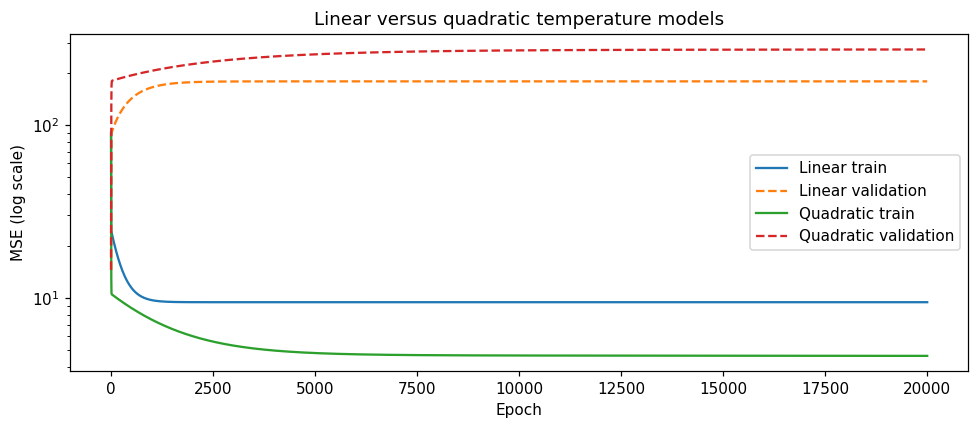

第 5 题自检通过：两组曲线均为有限值，训练损失下降；划分、缩放和训练循环保持不变。


In [6]:
# Chapter 4 示例代码：数据预处理
import torch
import torch.optim as optim
import matplotlib.pyplot as plt

torch.manual_seed(42)

t_c = [0.5, 14.0, 15.0, 28.0, 11.0, 8.0, 3.0, 4.0, 6.0, 13.0, 21.0]
t_u = [35.7, 55.9, 58.2, 81.9, 56.3, 84.9, 33.9, 21.8, 48.4, 60.4, 68.4]

t_c = torch.tensor(t_c)
t_u = torch.tensor(t_u)

n_samples = t_u.shape[0]
n_val = int(0.2 * n_samples)  # train:num : val:num = 8:2

shuffled_indices = torch.randperm(n_samples)  # 将 index 随机打乱
train_indices = shuffled_indices[:-n_val]
val_indices = shuffled_indices[-n_val:]

train_t_u = t_u[train_indices]
train_t_c = t_c[train_indices]
val_t_u = t_u[val_indices]
val_t_c = t_c[val_indices]

train_t_un = 0.1 * train_t_u
val_t_un = 0.1 * val_t_u

params = torch.tensor([0.0, 1.0, 0.0], requires_grad=True)

def model(t_u, w2, w1, b):
    return w2 * t_u ** 2 + w1 * t_u + b

def linear_model(t_u, w, b):
    return w * t_u + b

optimizer = optim.SGD([params], lr=1e-4)

# 损失函数：不需要因为模型从线性变为二次而改变。
def loss_fn(t_p, t_c):
    squared_diffs = (t_p - t_c) ** 2
    return squared_diffs.mean()

# 训练循环：请根据你的模型参数数量检查 model(t_u, *params) 是否仍然适用。
def training_loop(
    n_epochs, optimizer, params,
    train_t_u, val_t_u, train_t_c, val_t_c, model
):
    train_loss_list = []
    val_loss_list = []

    for epoch in range(1, n_epochs + 1):
        train_t_p = model(train_t_u, *params)
        train_loss = loss_fn(train_t_p, train_t_c)

        with torch.no_grad():
            val_t_p = model(val_t_u, *params)
            val_loss = loss_fn(val_t_p, val_t_c)

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        train_loss_list.append(train_loss.item())
        val_loss_list.append(val_loss.item())

    return train_loss_list, val_loss_list


n_epochs = 20000
linear_params = torch.tensor([1.0, 0.0], requires_grad=True)
linear_optimizer = optim.SGD([linear_params], lr=1e-2)
linear_train_losses, linear_val_losses = training_loop(
    n_epochs, linear_optimizer, linear_params,
    train_t_un, val_t_un, train_t_c, val_t_c, linear_model,
)
quadratic_train_losses, quadratic_val_losses = training_loop(
    n_epochs, optimizer, params,
    train_t_un, val_t_un, train_t_c, val_t_c, model,
)

temperature_results = {}
with torch.no_grad():
    for name, fitted_model, fitted_params, train_history, val_history in (
        ("Linear", linear_model, linear_params, linear_train_losses, linear_val_losses),
        ("Quadratic", model, params, quadratic_train_losses, quadratic_val_losses),
    ):
        assert np.isfinite(train_history).all() and np.isfinite(val_history).all()
        assert train_history[-1] < train_history[0]
        final_train = loss_fn(fitted_model(train_t_un, *fitted_params), train_t_c).item()
        final_val = loss_fn(fitted_model(val_t_un, *fitted_params), val_t_c).item()
        temperature_results[name] = {"train_mse": final_train, "val_mse": final_val}
        print(f"{name}: params={fitted_params.detach().tolist()}, train MSE={final_train:.6f}, val MSE={final_val:.6f}")
    print("训练/验证数量：", len(train_indices), len(val_indices))
    print("验证输入（缩放前）：", val_t_u.tolist(), "验证目标：", val_t_c.tolist())
    print("线性验证预测：", linear_model(val_t_un, *linear_params).tolist())
    print("二次验证预测：", model(val_t_un, *params).tolist())

figure, axis = plt.subplots(figsize=(9, 4))
epoch_axis = np.arange(1, n_epochs + 1)
axis.plot(epoch_axis, linear_train_losses, label="Linear train")
axis.plot(epoch_axis, linear_val_losses, "--", label="Linear validation")
axis.plot(epoch_axis, quadratic_train_losses, label="Quadratic train")
axis.plot(epoch_axis, quadratic_val_losses, "--", label="Quadratic validation")
axis.set(xlabel="Epoch", ylabel="MSE (log scale)", title="Linear versus quadratic temperature models")
axis.set_yscale("log")
axis.legend()
figure.tight_layout()
plt.show()
print("第 5 题自检通过：两组曲线均为有限值，训练损失下降；划分、缩放和训练循环保持不变。")


### 第 5 题分析

- 保留题目给定的 11 个样本、随机划分方式、0.1 倍输入缩放、MSE 和训练循环。固定随机种子后，两模型共享同一训练/验证集。由于 int(0.2×11)=2，实际是 9 个训练样本、2 个验证样本。
- 二次模型为 w2×t_u²+w1×t_u+b；这里传入的 t_u 是缩放后的输入，三个参数仍可用 *params 解包。二次项初值为 0，使两模型起始预测一致。
- 线性 SGD 学习率保留 0.01。平方输入放大了梯度曲率，二次模型改为 0.0001 以避免发散；两者各训练 20000 轮。没有更改给定训练循环：曲线记录每次更新前的损失，表格则重新计算最后一次更新后的损失。
- 本机 CPU 实测：线性模型最终训练/验证 MSE 为 9.4410/178.9247，二次模型为 4.6188/273.5958。二次模型训练误差更小，但验证误差更大，说明更好地拟合训练集不等于更好的泛化。不同学习率和特征条件数也影响收敛速度，不能仅凭模型参数数量解释所有损失差异。
- 本题原始数据包含 (84.9, 8.0)，与其他样本总体趋势不一致，且此次恰好进入验证集。它与第 6 题的 (48.9, 8.0) 不同；题目要求保留数据，因此不擅自“修正”。二次曲线在高输入处预测更高，使该验证点误差尤其大。
- 只有 2 个验证样本，观察对划分及异常样本非常敏感。二次模型呈现更大的泛化差距/过拟合风险，但要得出稳健结论还应采用更多数据或多次划分，而不是用验证结果反过来修改标签。


## 6. Chapter 5.1：简单神经网络实验

下面的代码来自课程示例截图，已经给出温度数据、8:2 随机划分和输入缩放。请在此基础上设计一个包含隐藏层的回归网络，并完成实验：

1. 实验隐藏层神经元数量和学习率，至少比较三组设置。
2. 绘制训练损失和验证损失。
3. 找到一个输出更接近原始温度数据趋势的设置。
4. 尝试让模型明显过拟合，并根据训练/验证损失解释判断依据。

h=4, lr=0.01: parameters=13, train MSE=0.846116, val MSE=3.799025
h=16, lr=0.01: parameters=49, train MSE=1.455266, val MSE=2.160198
h=16, lr=0.001: parameters=49, train MSE=4.709687, val MSE=2.908346
Overfit: 128x128, lr=0.003: parameters=16897, train MSE=0.000000, val MSE=6.776361
三组常规设置中最终验证 MSE 最小： h=16, lr=0.01
大网络最佳验证轮次=134, 当时 train/val MSE=2.458908/1.144825; 最终 train/val MSE=0.000000/6.776361
是否观察到训练近乎零误差且验证误差较最佳点明显上升： True


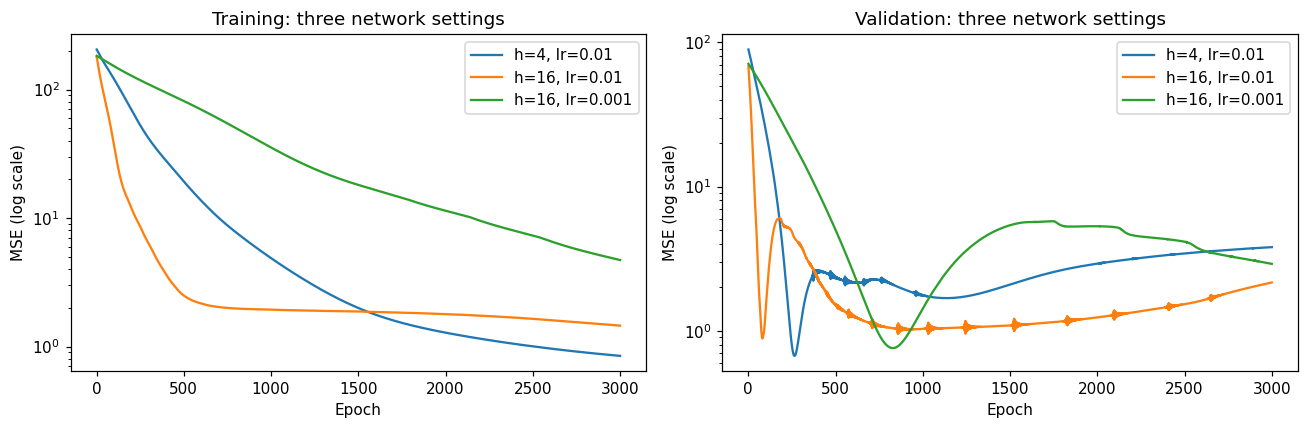

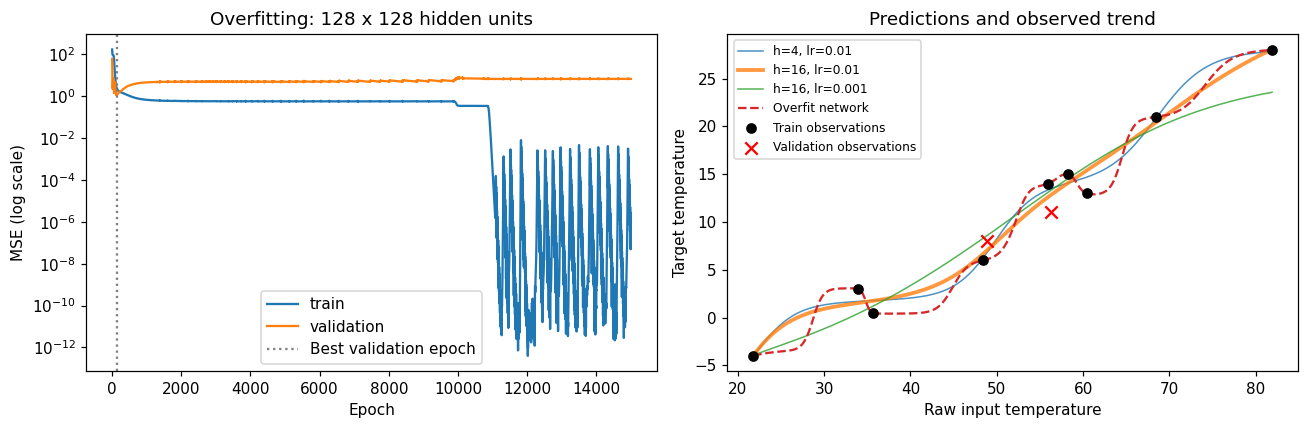

第 6 题自检通过：三组常规设置及过拟合实验损失均有限，训练损失下降。


In [7]:
# Chapter 5.1 示例代码：定义目标和输入数据
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)
t_c = [0.5, 14.0, 15.0, 28.0, 11.0, 8.0, 3.0, -4.0, 6.0, 13.0, 21.0]
t_u = [35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4]

# 转换为 PyTorch 张量并增加一个维度
t_c = torch.tensor(t_c).unsqueeze(1)
t_u = torch.tensor(t_u).unsqueeze(1)

# 数据划分
n_samples = t_u.shape[0]
n_val = int(0.2 * n_samples)

# 随机打乱数据顺序
shuffle_ind = torch.randperm(n_samples)

# 划分训练集和验证集的索引
train_ind = shuffle_ind[:-n_val]
val_ind = shuffle_ind[-n_val:]

# 根据索引划分训练集和验证集
train_t_u = t_u[train_ind]
train_t_c = t_c[train_ind]
val_t_u = t_u[val_ind]
val_t_c = t_c[val_ind]

# 缩放训练集和验证集的输入数据
train_t_un = 0.1 * train_t_u
val_t_un = 0.1 * val_t_u


def run_temperature_network(hidden_width, learning_rate, epochs, hidden_layers=1):
    torch.manual_seed(42)
    layers = [nn.Linear(1, hidden_width), nn.Tanh()]
    for layer_index in range(hidden_layers - 1):
        layers.extend([nn.Linear(hidden_width, hidden_width), nn.Tanh()])
    layers.append(nn.Linear(hidden_width, 1))
    network = nn.Sequential(*layers)
    network_optimizer = torch.optim.Adam(network.parameters(), lr=learning_rate)
    history = {"train": [], "validation": []}
    for epoch in range(epochs):
        network.train()
        network_optimizer.zero_grad()
        train_loss = nn.functional.mse_loss(network(train_t_un), train_t_c)
        train_loss.backward()
        network_optimizer.step()
        network.eval()
        with torch.no_grad():
            history["train"].append(nn.functional.mse_loss(network(train_t_un), train_t_c).item())
            history["validation"].append(nn.functional.mse_loss(network(val_t_un), val_t_c).item())
    assert np.isfinite(history["train"]).all() and np.isfinite(history["validation"]).all()
    assert history["train"][-1] < history["train"][0]
    return {
        "network": network,
        "history": history,
        "parameters": sum(parameter.numel() for parameter in network.parameters()),
    }

network_settings = [
    ("h=4, lr=0.01", 4, 0.01),
    ("h=16, lr=0.01", 16, 0.01),
    ("h=16, lr=0.001", 16, 0.001),
]
network_results = {}
for setting_name, hidden_width, learning_rate in network_settings:
    network_results[setting_name] = run_temperature_network(hidden_width, learning_rate, epochs=3000)

best_setting = min(
    network_results, key=lambda name: network_results[name]["history"]["validation"][-1]
)
overfit_result = run_temperature_network(128, 0.003, epochs=15000, hidden_layers=2)
for setting_name, result in [*network_results.items(), ("Overfit: 128x128, lr=0.003", overfit_result)]:
    history = result["history"]
    print(f"{setting_name}: parameters={result['parameters']}, train MSE={history['train'][-1]:.6f}, val MSE={history['validation'][-1]:.6f}")
print("三组常规设置中最终验证 MSE 最小：", best_setting)

overfit_history = overfit_result["history"]
best_overfit_epoch = int(np.argmin(overfit_history["validation"]))
print(
    f"大网络最佳验证轮次={best_overfit_epoch + 1}, "
    f"当时 train/val MSE={overfit_history['train'][best_overfit_epoch]:.6f}/"
    f"{overfit_history['validation'][best_overfit_epoch]:.6f}; "
    f"最终 train/val MSE={overfit_history['train'][-1]:.6f}/"
    f"{overfit_history['validation'][-1]:.6f}"
)
overfitting_observed = (
    overfit_history["train"][-1] < 0.01
    and overfit_history["validation"][-1] > 2 * overfit_history["validation"][best_overfit_epoch]
)
print("是否观察到训练近乎零误差且验证误差较最佳点明显上升：", overfitting_observed)

figure, axes = plt.subplots(1, 2, figsize=(12, 4))
for setting_name, result in network_results.items():
    for axis, split in zip(axes, ("train", "validation")):
        axis.plot(np.arange(1, 3001), result["history"][split], label=setting_name)
for axis, split in zip(axes, ("Training", "Validation")):
    axis.set(xlabel="Epoch", ylabel="MSE (log scale)", title=f"{split}: three network settings")
    axis.set_yscale("log")
    axis.legend()
figure.tight_layout()
plt.show()

figure, axes = plt.subplots(1, 2, figsize=(12, 4))
for split in ("train", "validation"):
    axes[0].plot(np.arange(1, 15001), overfit_history[split], label=split)
axes[0].axvline(best_overfit_epoch + 1, color="gray", linestyle=":", label="Best validation epoch")
axes[0].set(xlabel="Epoch", ylabel="MSE (log scale)", title="Overfitting: 128 x 128 hidden units")
axes[0].set_yscale("log")
axes[0].legend()
input_grid = torch.linspace(t_u.min().item(), t_u.max().item(), 300).unsqueeze(1)
with torch.no_grad():
    for setting_name, result in network_results.items():
        axes[1].plot(input_grid.squeeze().numpy(), result["network"](0.1 * input_grid).squeeze().numpy(),
                     label=setting_name, linewidth=2.5 if setting_name == best_setting else 1, alpha=0.8)
    axes[1].plot(input_grid.squeeze().numpy(), overfit_result["network"](0.1 * input_grid).squeeze().numpy(),
                 "--", label="Overfit network")
axes[1].scatter(train_t_u.numpy(), train_t_c.numpy(), color="black", label="Train observations", zorder=3)
axes[1].scatter(val_t_u.numpy(), val_t_c.numpy(), color="red", marker="x", s=65, label="Validation observations", zorder=3)
axes[1].set(xlabel="Raw input temperature", ylabel="Target temperature", title="Predictions and observed trend")
axes[1].legend(fontsize=8)
figure.tight_layout()
plt.show()
print("第 6 题自检通过：三组常规设置及过拟合实验损失均有限，训练损失下降。")


### 第 6 题分析

- 保留原始数据、随机划分和 0.1 倍缩放。三个常规实验使用一个 Tanh 隐藏层和线性输出层，比较 (4, 0.01)、(16, 0.01)、(16, 0.001)，括号内为隐藏宽度和 Adam 学习率；同一划分上各训练 3000 轮，初始化均重置随机种子。
- 本机三组最终训练/验证 MSE 依次为 0.8461/3.7993、1.4552/2.1601、4.7097/2.9073。选取隐藏宽度 16、学习率 0.01，并在预测图中加粗该曲线，它跟随整体温度上升趋势。0.001 学习率的收敛更慢；宽度 4 的训练误差更低，却没有更好的验证表现。
- 过拟合实验使用两层各 128 个 Tanh 神经元、Adam 学习率 0.003、训练 15000 轮，无权重衰减和早停。本机第 134 轮训练/验证 MSE 为 2.4589/1.1448，最后约为 7.16×10⁻⁷/6.7814；训练误差接近零而验证误差反而升高，说明继续拟合训练集细节降低了泛化表现。判断依据是损失差距及其随训练变化，不只是“网络很大”。
- 预测图也把训练点与验证点区分展示。验证集仅有两个点，恰好集中在中间温度附近，因此局部验证表现不能充分描述整个输入区间；本次选择是调参结果，而非独立测试集上的泛化结论。
- 实际应用可减少模型复杂度、加权重衰减，并按验证损失早停；最终仍需额外测试集或交叉验证。本节数据很小，全部在 CPU 运行，不需要 GPU。


## 7. 白酒质量数据分类

使用 `winequality-white.csv` 构造分类模型。文件使用分号分隔，最后一列 `quality` 是标签。

要求：

1. 按 8:2 划分训练集和验证集。
2. 只使用训练集统计量对特征进行 normalization，再应用到验证集。
3. 根据输入特征数量设计分类网络。
4. 训练模型并绘制损失曲线和准确率曲线。
5. 绘制混淆矩阵或其他能够体现分类效果的图。
6. 分析数据规模、特征维度、模型复杂度、优化器和训练轮数对训练时间的影响。

epoch=  1, train/val loss=1.4846/1.4613, train/val accuracy=44.37%/46.58%


epoch= 50, train/val loss=0.9425/0.9741, train/val accuracy=60.07%/59.35%


epoch=100, train/val loss=0.8459/0.9702, train/val accuracy=64.81%/58.32%


epoch=150, train/val loss=0.7839/1.0068, train/val accuracy=68.10%/58.02%
数据：4898 行、11 个特征、7 类；训练/验证=3919/979
原始质量分数： [3, 4, 5, 6, 7, 8, 9]
训练类别数： [16, 129, 1173, 1742, 703, 151, 5]
验证类别数： [4, 34, 284, 456, 177, 24, 0]
完全重复的额外记录：937；本实验遵循题目采用随机行划分。
参数数量：3,079
训练时间：12.118 s，平均每 epoch：0.0808 s，device=cuda
最佳验证损失 checkpoint：epoch 72，loss=0.9546，accuracy=59.04%
多数类基线：46.58%；macro-F1：0.3447；macro-recall：0.3240
quality=3, support=4, precision=0.250, recall=0.250, F1=0.250
quality=4, support=34, precision=0.571, recall=0.235, F1=0.333
quality=5, support=284, precision=0.567, recall=0.553, F1=0.560
quality=6, support=456, precision=0.594, recall=0.719, F1=0.651
quality=7, support=177, precision=0.634, recall=0.469, F1=0.539
quality=8, support=24, precision=1.000, recall=0.042, F1=0.080
quality=9, support=0, precision=0.000, recall=0.000, F1=0.000


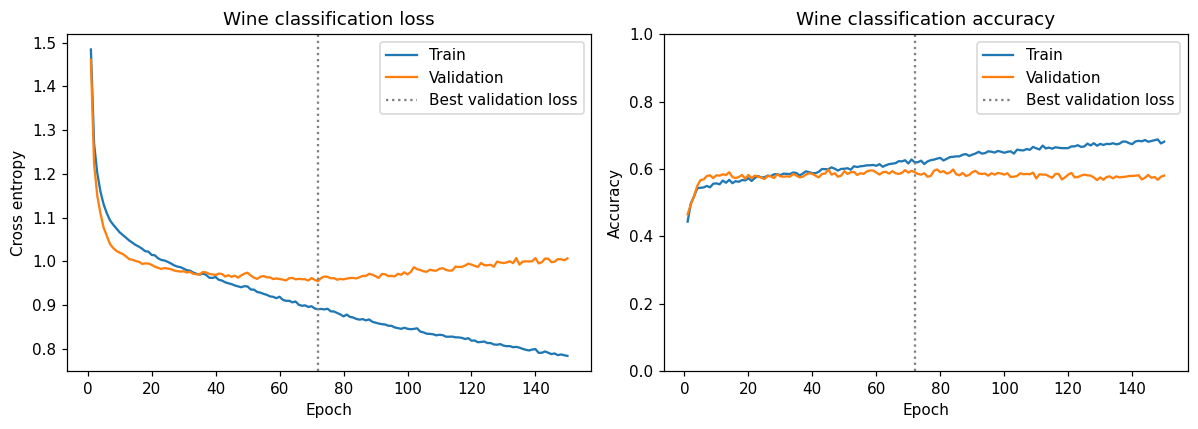

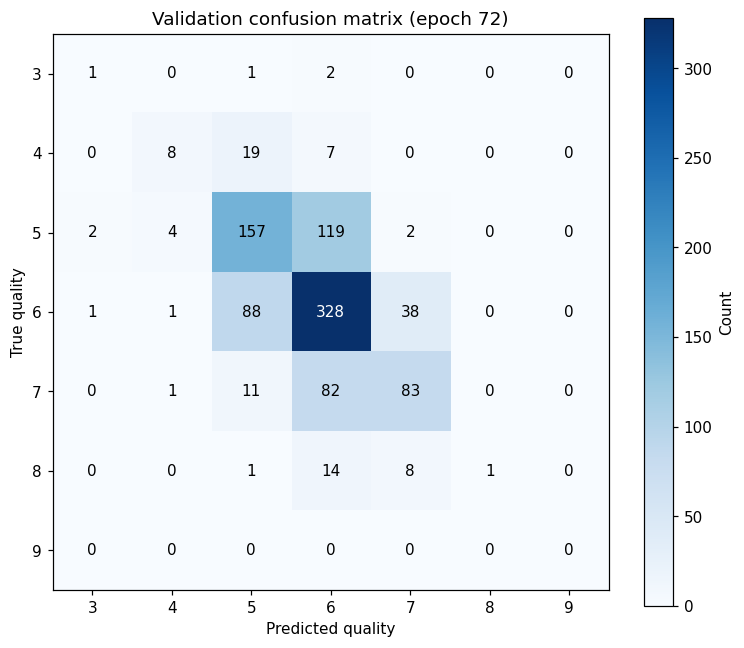

第 7 题自检通过：划分无重叠、训练统计量标准化、训练有限且收敛、混淆矩阵计数正确。


In [8]:
torch.manual_seed(42)
np.random.seed(42)
with (DATA_DIR / "winequality-white.csv").open(newline="", encoding="utf-8-sig") as csv_file:
    reader = csv.reader(csv_file, delimiter=";")
    wine_columns = next(reader)
    wine_data = np.asarray([[float(value) for value in row] for row in reader], dtype=np.float64)

assert wine_columns[-1] == "quality"
assert wine_data.ndim == 2 and wine_data.shape[1] == len(wine_columns)
assert np.isfinite(wine_data).all()
assert np.equal(wine_data[:, -1], np.floor(wine_data[:, -1])).all()
wine_features = torch.tensor(wine_data[:, :-1], dtype=torch.float32)
wine_quality = torch.tensor(wine_data[:, -1], dtype=torch.int64)
quality_values, wine_targets = torch.unique(wine_quality, sorted=True, return_inverse=True)
num_features = wine_features.shape[1]
num_classes = len(quality_values)

wine_indices = torch.randperm(len(wine_features))
wine_val_count = int(0.2 * len(wine_features))
wine_train_indices = wine_indices[:-wine_val_count]
wine_val_indices = wine_indices[-wine_val_count:]
wine_train_raw = wine_features[wine_train_indices]
wine_val_raw = wine_features[wine_val_indices]
wine_train_targets = wine_targets[wine_train_indices]
wine_val_targets = wine_targets[wine_val_indices]

feature_mean = wine_train_raw.mean(dim=0)
feature_std = wine_train_raw.std(dim=0, unbiased=False).clamp_min(1e-6)
wine_train_features = (wine_train_raw - feature_mean) / feature_std
wine_val_features = (wine_val_raw - feature_mean) / feature_std

assert len(set(wine_train_indices.tolist()) & set(wine_val_indices.tolist())) == 0
assert len(wine_train_indices) + len(wine_val_indices) == len(wine_features)
torch.testing.assert_close(wine_train_features.mean(dim=0), torch.zeros(num_features), atol=1e-4, rtol=0)
torch.testing.assert_close(wine_train_features.std(dim=0, unbiased=False), torch.ones(num_features), atol=1e-4, rtol=1e-4)
assert torch.isfinite(wine_train_features).all() and torch.isfinite(wine_val_features).all()

wine_model = nn.Sequential(
    nn.Linear(num_features, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, num_classes),
).to(device)
wine_optimizer = torch.optim.Adam(wine_model.parameters(), lr=0.001, weight_decay=1e-4)
wine_loss_fn = nn.CrossEntropyLoss()
wine_dataset = torch.utils.data.TensorDataset(wine_train_features, wine_train_targets)
wine_loader = torch.utils.data.DataLoader(
    wine_dataset, batch_size=128, shuffle=True, num_workers=0,
    generator=torch.Generator().manual_seed(42),
)
wine_train_on_device = wine_train_features.to(device)
wine_val_on_device = wine_val_features.to(device)
wine_train_targets_on_device = wine_train_targets.to(device)
wine_val_targets_on_device = wine_val_targets.to(device)
wine_epochs = 150
wine_history = {"train_loss": [], "val_loss": [], "train_accuracy": [], "val_accuracy": []}
wine_best_val_loss = float("inf")
wine_best_epoch = 0
wine_best_state = None
synchronize_device()
wine_started_at = time.perf_counter()
for epoch in range(1, wine_epochs + 1):
    wine_model.train()
    for batch_features, batch_targets in wine_loader:
        batch_features = batch_features.to(device)
        batch_targets = batch_targets.to(device)
        wine_optimizer.zero_grad()
        logits = wine_model(batch_features)
        batch_loss = wine_loss_fn(logits, batch_targets)
        batch_loss.backward()
        wine_optimizer.step()
    wine_model.eval()
    with torch.no_grad():
        train_logits = wine_model(wine_train_on_device)
        val_logits = wine_model(wine_val_on_device)
        train_loss = wine_loss_fn(train_logits, wine_train_targets_on_device).item()
        val_loss = wine_loss_fn(val_logits, wine_val_targets_on_device).item()
        train_accuracy = (train_logits.argmax(dim=1) == wine_train_targets_on_device).float().mean().item()
        val_accuracy = (val_logits.argmax(dim=1) == wine_val_targets_on_device).float().mean().item()
    for key, value in (
        ("train_loss", train_loss), ("val_loss", val_loss),
        ("train_accuracy", train_accuracy), ("val_accuracy", val_accuracy),
    ):
        wine_history[key].append(value)
    if val_loss < wine_best_val_loss:
        wine_best_val_loss = val_loss
        wine_best_epoch = epoch
        wine_best_state = copy.deepcopy(wine_model.state_dict())
    if epoch == 1 or epoch % 50 == 0:
        print(f"epoch={epoch:3d}, train/val loss={train_loss:.4f}/{val_loss:.4f}, train/val accuracy={train_accuracy:.2%}/{val_accuracy:.2%}")
synchronize_device()
wine_training_seconds = time.perf_counter() - wine_started_at

assert all(np.isfinite(values).all() for values in wine_history.values())
assert wine_history["train_loss"][-1] < wine_history["train_loss"][0]
assert wine_best_state is not None
wine_model.load_state_dict(wine_best_state)
wine_model.eval()
with torch.no_grad():
    wine_predictions = wine_model(wine_val_on_device).argmax(dim=1).cpu()
confusion = torch.bincount(
    wine_val_targets * num_classes + wine_predictions,
    minlength=num_classes ** 2,
).reshape(num_classes, num_classes).numpy()
assert int(confusion.sum()) == len(wine_val_targets)
assert confusion.shape == (num_classes, num_classes)
assert wine_predictions.min() >= 0 and wine_predictions.max() < num_classes
best_wine_accuracy = float(np.trace(confusion) / confusion.sum())
assert abs(best_wine_accuracy - wine_history["val_accuracy"][wine_best_epoch - 1]) < 1e-6
class_precision = np.divide(np.diag(confusion), confusion.sum(axis=0),
                            out=np.zeros(num_classes), where=confusion.sum(axis=0) != 0)
class_recall = np.divide(np.diag(confusion), confusion.sum(axis=1),
                         out=np.zeros(num_classes), where=confusion.sum(axis=1) != 0)
class_f1 = np.divide(2 * class_precision * class_recall, class_precision + class_recall,
                     out=np.zeros(num_classes), where=class_precision + class_recall != 0)
majority_class = torch.bincount(wine_train_targets, minlength=num_classes).argmax()
majority_accuracy = (wine_val_targets == majority_class).float().mean().item()
duplicate_rows = len(wine_data) - len(np.unique(wine_data, axis=0))
print(f"数据：{len(wine_features)} 行、{num_features} 个特征、{num_classes} 类；训练/验证={len(wine_train_indices)}/{len(wine_val_indices)}")
print("原始质量分数：", quality_values.tolist())
print("训练类别数：", torch.bincount(wine_train_targets, minlength=num_classes).tolist())
print("验证类别数：", torch.bincount(wine_val_targets, minlength=num_classes).tolist())
print(f"完全重复的额外记录：{duplicate_rows}；本实验遵循题目采用随机行划分。")
print(f"参数数量：{sum(parameter.numel() for parameter in wine_model.parameters()):,}")
print(f"训练时间：{wine_training_seconds:.3f} s，平均每 epoch：{wine_training_seconds / wine_epochs:.4f} s，device={device}")
print(f"最佳验证损失 checkpoint：epoch {wine_best_epoch}，loss={wine_best_val_loss:.4f}，accuracy={best_wine_accuracy:.2%}")
print(f"多数类基线：{majority_accuracy:.2%}；macro-F1：{class_f1.mean():.4f}；macro-recall：{class_recall.mean():.4f}")
for quality, support, precision, recall, f1_score in zip(
    quality_values.tolist(), confusion.sum(axis=1), class_precision, class_recall, class_f1
):
    print(f"quality={quality}, support={support}, precision={precision:.3f}, recall={recall:.3f}, F1={f1_score:.3f}")

figure, axes = plt.subplots(1, 2, figsize=(11, 4))
wine_epoch_axis = np.arange(1, wine_epochs + 1)
for split, label in (("train", "Train"), ("val", "Validation")):
    axes[0].plot(wine_epoch_axis, wine_history[f"{split}_loss"], label=label)
    axes[1].plot(wine_epoch_axis, wine_history[f"{split}_accuracy"], label=label)
for axis in axes:
    axis.axvline(wine_best_epoch, linestyle=":", color="gray", label="Best validation loss")
    axis.set_xlabel("Epoch")
    axis.legend()
axes[0].set(ylabel="Cross entropy", title="Wine classification loss")
axes[1].set(ylabel="Accuracy", title="Wine classification accuracy", ylim=(0, 1))
figure.tight_layout()
plt.show()

figure, axis = plt.subplots(figsize=(7, 6))
matrix_image = axis.imshow(confusion, cmap="Blues")
figure.colorbar(matrix_image, ax=axis, label="Count")
axis.set(
    xticks=np.arange(num_classes), yticks=np.arange(num_classes),
    xticklabels=quality_values.tolist(), yticklabels=quality_values.tolist(),
    xlabel="Predicted quality", ylabel="True quality",
    title=f"Validation confusion matrix (epoch {wine_best_epoch})",
)
for row_index in range(num_classes):
    for column_index in range(num_classes):
        count = int(confusion[row_index, column_index])
        axis.text(column_index, row_index, str(count), ha="center", va="center",
                  color="white" if count > confusion.max() / 2 else "black")
figure.tight_layout()
plt.show()
print("第 7 题自检通过：划分无重叠、训练统计量标准化、训练有限且收敛、混淆矩阵计数正确。")


### 第 7 题分析

- 按固定随机种子作样本行级 8:2 划分，只使用训练特征的均值和总体标准差进行 z-score 标准化；验证集不能单独拟合标准化参数。标签从原始质量分数映射到连续的 0…K−1，显示时再使用真实分数。
- 输入维度由 CSV 实际特征数决定，网络为 11→64→32→7，使用 ReLU、Adam、交叉熵以及少量权重衰减。输出层保留 logits，不在 CrossEntropyLoss 前重复加 softmax。
- 输出同时报告最后一轮指标、最低验证损失 checkpoint 的准确率、多数类基线、macro-F1 和逐类指标。曲线保留完整 150 轮；混淆矩阵使用最佳验证损失 checkpoint，不能误认为它对应最后一轮。
- 本机最低验证损失出现在第 72 轮：交叉熵 0.9543、准确率 59.24%，高于多数类基线 46.58%。最后一轮训练/验证准确率为 68.18%/58.22%，训练继续改善而验证损失从最佳值升到 1.0073，呈现过拟合迹象。150 轮训练及评估实测约 2.24 秒。
- 混淆矩阵行是真实类别、列是预测类别。质量 6 最常见，质量 8 的召回率仅约 4.2%；质量 9 在本次验证集没有样本，不能据此评估该类的识别能力。macro-F1=0.3454 按完整 7 类平均，分母为零的指标置 0；macro-recall 同样采用这一约定，并非只对有验证样本的类别平均。少数类/缺失类别使单看准确率不充分。验证集同时用于选轮次，因此这些数值不是独立测试性能。
- 约 4900 条数据和 11 维输入在 CPU 上即可快速训练。每轮主要计算成本随样本数及各层输入×输出维度增长；增加特征、隐藏层宽度/深度会增加计算量、参数和激活内存。宽隐藏层之间的连接数近似随宽度平方增长。
- 总时间通常随 epoch 数近似线性增长；batch 太小会增加 Python/优化器调用次数，太大可能增加内存需求并改变优化表现。Adam 比朴素 SGD 多维护一阶/二阶状态，单步时间与内存更高，但可能更快达到目标损失。GPU 小任务还可能被启动与传输开销主导。
- 上方时间覆盖训练、每轮评估和最佳权重复制，不含读 CSV、标准化、构建网络或画图；CUDA 时在起止处同步。只测量了当前设置，不把关于规模和优化器的复杂度分析说成已完成的对照实验。
- 此 CSV 中存在完全重复的记录，数量见输出。题目要求的随机行划分可能让重复样本跨训练/验证集，导致验证表现偏乐观；若评估独立样本泛化，应另做按重复记录分组的划分，而不能将当前结果当作严格无重复测试。


## 提交要求

提交填写完成后的 Notebook（ipynb文件），或导出为 PDF。请确保代码、图表和文字分析均已保留。

## 本地验证与服务器待跑项

- **已在本机 CPU 验证**：第 1–7 题全部代码、断言、训练和图表；第 4 题仅 CPU 数值/存储地址检查。
- **服务器必补的 GPU 专项**：第 3 题 CUDA 三种矩阵乘法计时；第 4 题 CUDA 当前/峰值显存比较。直接在可用 CUDA 的 PyTorch 环境顺序重跑本 Notebook 即可，默认会选择 CUDA。
- **不需要 GPU**：文本编码、温度模型、神经网络过拟合实验及酒质量分类均已在 CPU 完成。
- **可选扩展**：将第 3 题 n 改为 5000；双循环会很慢，不纳入默认验证。
- 可运行 `python homework1/run_notebook.py --device cpu` 复现；服务器运行 `python run_notebook.py --device cuda --output /tmp/homework1-cuda.ipynb` 可另存 GPU 输出，不覆盖本地 CPU 记录。环境安装和更完整说明见同目录 README.md。
